In [1]:

import pandas as pd

# Load dataset
df = pd.read_parquet("../data/bronze/train.parquet")

# Show first 10 articles
display(df.head(10))


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2
5,"Stocks End Up, But Near Year Lows (Reuters) Re...",2
6,Money Funds Fell in Latest Week (AP) AP - Asse...,2
7,Fed minutes show dissent over inflation (USATO...,2
8,Safety Net (Forbes.com) Forbes.com - After ear...,2
9,Wall St. Bears Claw Back Into the Black NEW Y...,2


In [2]:
pd.set_option("display.max_colwidth", None)

display(df.sample(5, random_state=42))

,text,label
71787,"BBC set for major shake-up, claims newspaper London - The British Broadcasting Corporation, the world #39;s biggest public broadcaster, is to cut almost a quarter of its 28 000-strong workforce, in the biggest shake-up in its 82-year history, The Times newspaper in London said on Monday.",2
67218,Marsh averts cash crunch Embattled insurance broker #39;s banks agree to waive clause that may have prevented access to credit. NEW YORK (Reuters) - Marsh amp; McLennan Cos.,2
54066,"Jeter, Yankees Look to Take Control (AP) AP - Derek Jeter turned a season that started with a terrible slump into one of the best in his accomplished 10-year career.",1
7168,"Flying the Sun to Safety When the Genesis capsule comes back to Earth with its samples of the sun, helicopter pilots will be waiting for it, ready to snag it out of the sky.",3
29618,"Stocks Seen Flat as Nortel and Oil Weigh NEW YORK (Reuters) - U.S. stocks were set to open near unchanged on Thursday after a warning from technology bellwether Nortel Networks Corp. &lt;A HREF=""http://www.investor.reuters.com/FullQuote.aspx?ticker=NT.N target=/stocks/quickinfo/fullquote""&gt;NT.N&lt;/A&gt; dimmed hopes, while stubbornly high oil prices also weighed on sentiment.",2


In [3]:
from datasets import load_dataset

ds = load_dataset("fancyzhx/ag_news")

print(ds["train"].features["label"].names)

c:\Users\tasni\Desktop\mlops_classif_news\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['World', 'Sports', 'Business', 'Sci/Tech']


In [4]:
label_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

df["category"] = df["label"].map(label_names)

display(df[["text", "category"]].head())

,text,category
0,"Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.",Business
1,"Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.",Business
2,Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.,Business
3,"Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from the main pipeline in southern Iraq after\intelligence showed a rebel militia could strike\infrastructure, an oil official said on Saturday.",Business
4,"Oil prices soar to all-time record, posing new menace to US economy (AFP) AFP - Tearaway world oil prices, toppling records and straining wallets, present a new economic menace barely three months before the US presidential elections.",Business


In [5]:
# Dataset dimensions
print("Shape:", df.shape)

Shape: (120000, 3)


In [6]:
# Data types
print(df.dtypes)

text          str
label       int64
category      str
dtype: object


In [7]:
print(df.isnull().sum())

text        0
label       0
category    0
dtype: int64


In [8]:
# Number of duplicated records
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [9]:
# Articles per category
display(df["category"].value_counts())

category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64

In [11]:
!pip install matplotlib

In [14]:
import sys
print(sys.executable)

c:\Users\tasni\Desktop\mlops_classif_news\.venv\Scripts\python.exe


In [15]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 MB 2.8 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.3 MB 2.8 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.3 MB 2.7 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.3 MB 2.8 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.3 MB 3.1 MB/s eta 0:00:02
   ------------------- -------------------- 4.5/9.3 MB 3.3 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.3 MB 3.4 MB/s eta 0:00:02
   ---------------------------- ----------- 6.6/9.3 MB 3.6 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 3.9 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.3 MB 3.9 MB/s eta 0:00:01
   -----------------------------------

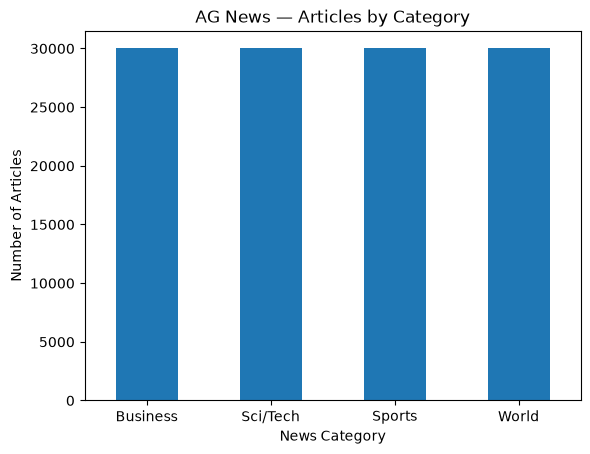

In [16]:
import matplotlib.pyplot as plt

df["category"].value_counts().plot(kind="bar")

plt.title("AG News — Articles by Category")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.show()